# Screen a small portfolio for extreme daily rainfall with CRC Open

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RiskThinking/crc-docs/blob/main/notebooks/sources/crc_open_hazards.ipynb) · [GitHub preview](https://github.com/RiskThinking/crc-docs/blob/main/notebooks/sources/crc_open_hazards.ipynb)

Compare **Rx1day**, the wettest day of the year (mm/day), at three illustrative
Toronto sites through this century with **CRC Open**, Riskthinking.AI's public
climate-distribution release.

What to know about CRC Open before reading the numbers:

- It covers **SSP5-8.5 only** (a high-emissions future) and has **no historical
  baseline**, so differences below are between future periods, not changes
  from today's climate.
- Its periods are **four-year windows** (2023–2026, 2028–2031, …, 2088–2091).
  A year such as 2050 selects the window that contains it (2048–2051).
- Values live on **H3 cells** (resolution 5, about 250 km²), so nearby sites can
  share a cell and a value. They are hazard return levels, not losses.

The sites are hypothetical. The headless twin is
[`pipelines/crc_open_pipeline.py`](../../pipelines/crc_open_pipeline.py).

## Prepare the runtime

In Colab choose **Runtime → Run all**. No credentials are needed. Set the
`CRC_OPEN_CATALOG` environment variable to read another CRC Open release index.

In [1]:
#@title Install dependencies and prepare this notebook
import importlib.util
import os
import subprocess
import sys

IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "--pre",
                           "--disable-pip-version-check", "crc-sdk>=1.0.0a3,<2", "plotly>=6"])

import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display

from crc_sdk import Assets, Bounds, Cache, CRCOpen, Runtime

STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
pio.templates.default = "plotly_white"
pio.defaults.default_width = 1000
pio.defaults.default_height = 470

CRC_OPEN = os.environ.get("CRC_OPEN_CATALOG", "https://data.riskthinking.ai/crc-open/_CURRENT.json")
RUNTIME = Runtime(cache=Cache.reuse("../data/crc_open/cache"))

## Discover what the release offers

`inspect()` reads only the release index: every variable, scenario and period
combination with its measurement, and no curves.

In [2]:
release = CRCOpen(catalog=CRC_OPEN)
series = release.inspect(runtime=RUNTIME).series
inventory = pd.DataFrame([
    dict(variable=s.variable.id, scenario=s.scenario.id if s.scenario else None,
         first=s.period.start, last=s.period.end,
         unit=str(getattr(getattr(s.measurement, "unit", None), "value", getattr(s.measurement, "unit", ""))))
    for s in series
])
display(inventory.groupby(["variable", "scenario"]).agg(
    windows=("first", "size"), first_year=("first", "min"), last_year=("last", "max"), unit=("unit", "first")))

,,windows,first_year,last_year,unit
variable,scenario,,,,
crc:dry_days,ssp585,14,2023.0,2091.0,days
crc:fwi,ssp585,14,2023.0,2091.0,dimensionless
crc:hot_days,ssp585,14,2023.0,2091.0,days
crc:max_consecutive_dry_days,ssp585,14,2023.0,2091.0,days
crc:prcptot,ssp585,14,2023.0,2091.0,mm
crc:rx1day,ssp585,14,2023.0,2091.0,mm/day
crc:tx_max,ssp585,14,2023.0,2091.0,K


## Choose sites, years and return periods

`YEARS` picks the four-year windows; `RETURN_PERIODS` are annual return periods
in years (a 100-year value has a 1% chance of being exceeded in a given year).
Only the release files covering a small box around the sites are read.

In [3]:
SITES = {
    "asset_id": ["West depot", "Central clinic", "East warehouse"],
    "longitude": [-79.47, -79.38, -79.29],
    "latitude": [43.65, 43.65, 43.70],
}
YEARS = [2030, 2050, 2080]
FOCUS_YEAR = 2050
RETURN_PERIODS = [2, 5, 10, 20, 50, 100]
AREA = Bounds(west=-79.52, south=43.60, east=-79.24, north=43.75)

rx1day = release.select(area=AREA, variables=CRCOpen.Variable.ANNUAL_MAXIMUM_DAILY_PRECIPITATION)
windows = sorted({s.period for s in rx1day.inspect(runtime=RUNTIME).series}, key=lambda p: p.start)
chosen = {year: next(p for p in windows if p.start <= year <= p.end) for year in YEARS}
label = {p.id: f"{p.start}-{p.end}" for p in windows}
print({year: label[p.id] for year, p in chosen.items()})

{2030: '2028-2031', 2050: '2048-2051', 2080: '2078-2081'}


## Evaluate the curves at the sites

`evaluate(Assets(...))` matches each site to the H3 cell that contains it and
reads that cell's published distribution at each return period. Nothing is
fitted. The result is in long format: one row per site, window and return
period, with `value` in mm/day and a `failure` code when a value is missing.

In [4]:
evaluation = (
    rx1day.select(periods=list(dict.fromkeys(chosen.values())))
    .evaluate(Assets(SITES))
    .return_periods(RETURN_PERIODS)
    .read(runtime=RUNTIME)
)
values = evaluation.table.to_pandas()
values["window"] = values.period_id.map(label)
print(f"{evaluation.report.counts.matched_assets} of {len(SITES['asset_id'])} sites matched a cell; "
      f"{values.failure.notna().sum()} rows without a value.")
display(values.pivot_table(index=["asset_id", "support_id"], columns=["window", "query_value"],
                           values="value").round(1))

3 of 3 sites matched a cell; 0 rows without a value.


window                            2028-2031                                \
query_value                           2.0   5.0   10.0  20.0  50.0  100.0   
asset_id       support_id                                                   
Central clinic h3:852b9bc7fffffff      34.6  43.2  49.0  54.6  61.8  67.2   
East warehouse h3:852b9bd7fffffff      38.1  47.7  54.1  60.2  68.1  74.0   
West depot     h3:852b9bc7fffffff      34.6  43.2  49.0  54.6  61.8  67.2   

window                            2048-2051                                \
query_value                           2.0   5.0   10.0  20.0  50.0  100.0   
asset_id       support_id                                                   
Central clinic h3:852b9bc7fffffff      37.4  50.3  58.8  66.9  77.5  85.4   
East warehouse h3:852b9bd7fffffff      40.1  54.1  63.5  72.5  84.1  92.9   
West depot     h3:852b9bc7fffffff      37.4  50.3  58.8  66.9  77.5  85.4   

window                            2078-2081                                
query_value                           2.0   5.0   10.0  20.0  50.0  100.0  
asset_id       support_id                                                  
Central clinic h3:852b9bc7fffffff      41.3  51.7  58.5  65.1  73.6  79.9  
East warehouse h3:852b9bd7fffffff      44.8  55.7  62.9  69.8  78.8  85.5  
West depot     h3:852b9bc7fffffff      41.3  51.7  58.5  65.1  73.6  79.9

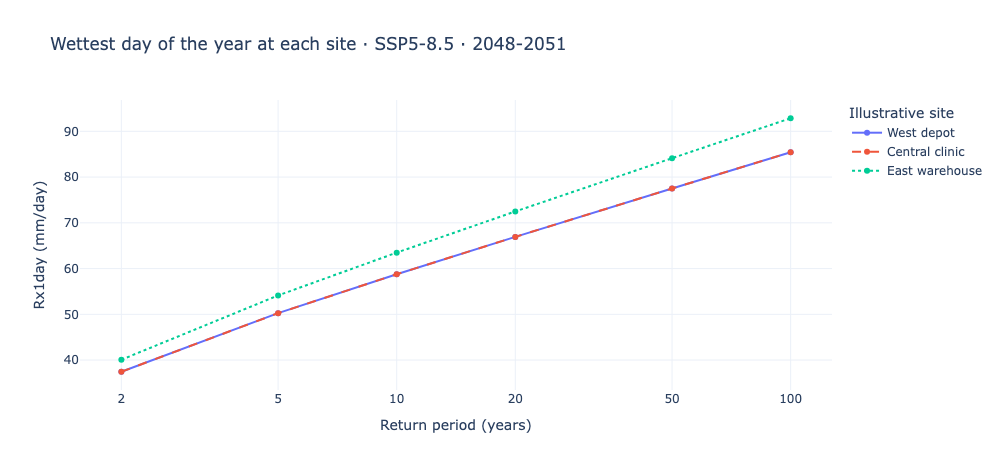

In [5]:
focus = values[values.window == label[chosen[FOCUS_YEAR].id]]
fig = go.Figure([
    go.Scatter(x=group.query_value, y=group.value, mode="lines+markers", name=site,
               line=dict(dash=("solid", "dash", "dot")[index % 3]))
    for index, (site, group) in enumerate(focus.groupby("asset_id", sort=False))
])
fig.update_layout(
    title=f"Wettest day of the year at each site · SSP5-8.5 · {label[chosen[FOCUS_YEAR].id]}",
    xaxis=dict(title="Return period (years)", type="log", tickvals=RETURN_PERIODS),
    yaxis_title="Rx1day (mm/day)", legend_title="Illustrative site",
)
fig.show()

## Compare future windows

The 100-year value in each window, relative to the first chosen window
(2028–2031). Both are SSP5-8.5 futures: this is change *within* the projection,
not change from a historical baseline. The chart reads every window in the
release for the same cells.

window,2028-2031,2048-2051,2078-2081,change 2028-2031 → 2048-2051 (%),change 2028-2031 → 2078-2081 (%)
asset_id,,,,,
Central clinic,67.2,85.4,79.9,27.2,19.0
East warehouse,74.0,92.9,85.5,25.4,15.5
West depot,67.2,85.4,79.9,27.2,19.0


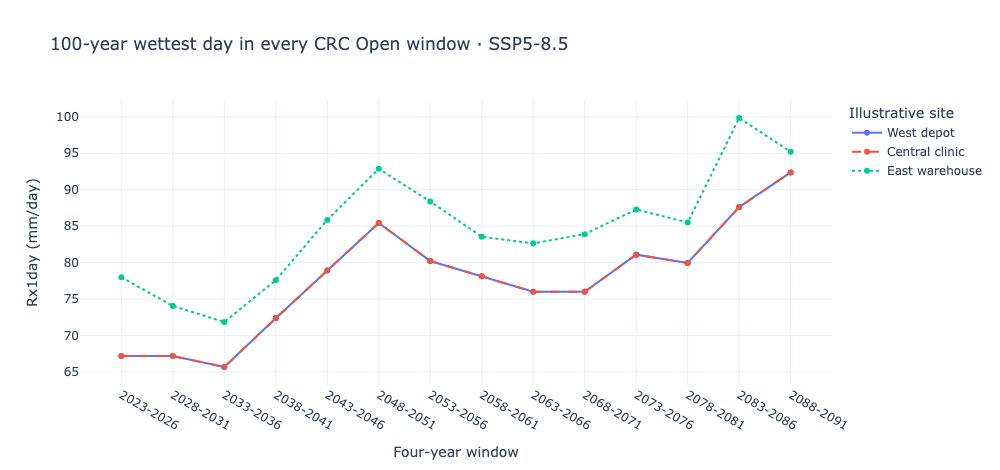

In [6]:
rp100 = values[values.query_value == 100].pivot(index="asset_id", columns="window", values="value")
first = label[chosen[YEARS[0]].id]
screening = rp100.copy()
for window in rp100.columns.drop(first):
    screening[f"change {first} → {window} (%)"] = (rp100[window] / rp100[first] - 1) * 100
display(screening.round(1))

every_window = (
    rx1day.evaluate(Assets(SITES)).return_periods([100]).read(runtime=RUNTIME).table.to_pandas()
)
every_window["start"] = every_window.period_id.map({p.id: p.start for p in windows})
fig = go.Figure([
    go.Scatter(x=[f"{s}-{s + 3}" for s in group.start], y=group.value, mode="lines+markers", name=site,
               line=dict(dash=("solid", "dash", "dot")[index % 3]))
    for index, (site, group) in enumerate(every_window.sort_values("start").groupby("asset_id", sort=False))
])
fig.update_layout(title="100-year wettest day in every CRC Open window · SSP5-8.5",
                  xaxis_title="Four-year window", yaxis_title="Rx1day (mm/day)", legend_title="Illustrative site")
fig.show()

## Provenance and reuse

Every result carries the release identity, licence and attribution. Keep them
with anything you export. CRC Open data is licensed **CC BY-NC 4.0**.

To screen your own sites from a terminal, pass a CSV or Parquet file with
`asset_id`, `longitude` and `latitude` columns:

```bash
uv run python pipelines/crc_open_pipeline.py --assets assets.csv --years 2030 2050 2080
```

For a historical cross-check, the [ERA5 notebook](era5_historical_baseline.ipynb)
fits a separate reanalysis baseline; it differs in source, period and method, so
its difference from CRC Open is not a pure climate-change signal.

In [7]:
source = evaluation.metadata.source
display(pd.Series({
    "release": source.release.id,
    "release sha256": source.release.sha256,
    "licence": source.resources[0].license,
    "attribution": source.resources[0].attribution,
}, name="CRC Open"))

release                        ssp585-global-2026-10-20-dataset2-v2
release sha256    sha256:a7e7c8385e33c44f667911767f1e238d505ec55...
licence                                                CC-BY-NC-4.0
attribution                                            RiskThinking
Name: CRC Open, dtype: str